In [1]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor

from IPython.display import Image

In [5]:
wine=pd.read_csv("D:\Machine Learning\Datasets\wine.csv")

100%|██████████| 4/4 [00:02<00:00,  1.53it/s]


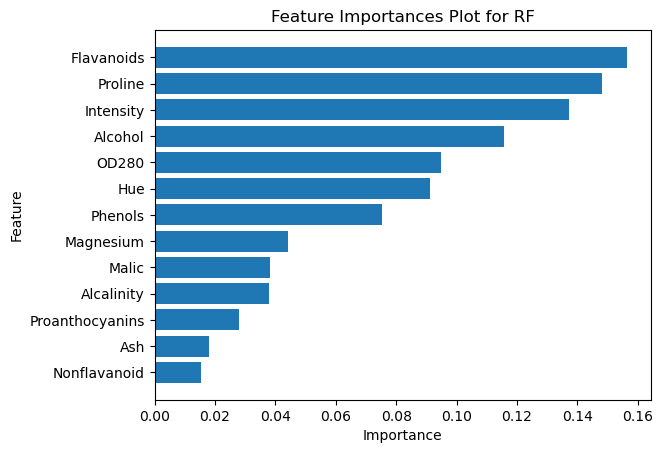

In [8]:
from sklearn.metrics import f1_score
from tqdm import tqdm


X, y = wine.drop("Class", axis=1), wine["Class"]
y.value_counts()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25, stratify=y)
features = [2, 3, 4, 5]
n_est = [25, 50, 100, 150, 200]
scores = []
for f in tqdm(features):
    for n in n_est:
        rf = RandomForestClassifier(n_estimators=n, max_features=f, random_state=25)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_test)
        scores.append([f, n, f1_score(y_test, y_pred, average='macro')])
scores_df = pd.DataFrame(scores, columns=["Features", "Trees", "score"])
scores_df.sort_values(by="score", ascending=False)
best_model = RandomForestClassifier(random_state=25, n_estimators=100, max_features=2)
best_model.fit(X, y)
df_imp = pd.DataFrame({"feature": X.columns, "importance": best_model.feature_importances_})
df_imp = df_imp.sort_values("importance")
import matplotlib.pyplot as plt
plt.barh(df_imp["feature"], df_imp["importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importances Plot for RF")
plt.show()